In [202]:
# plot distributions of population parameters on the sky
import numpy as np
import pandas as pd
from matplotlib import pyplot
import healpy
print(healpy.__version__)

import gammapy
#from gammapy.datasets import MapDataset
#from gammapy.makers import MapDatasetMaker, SafeMaskMaker
from gammapy.maps import HpxGeom, HpxNDMap


import os
import sys
if '../../lib/' not in sys.path:
    sys.path.append('../../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil


1.13.0


In [203]:
if 1:
    import importlib
    importlib.reload(util);


In [204]:
def get_xyz(df):
    res = np.zeros((3, len(df)))
    res[2] = df['sin(GLAT)']
    cos_glat = np.sqrt(1. - res[2]**2)
    res[0] = cos_glat * df['cos(GLON)']
    res[1] = cos_glat * df['sin(GLON)']
    return res

def cls2label(cls):
    label = cls[0]
    for cl in cls[1:]:
        label += ', %s' % cl
    return label

In [205]:
# parameters
order = 4
nside = int(2**order)
npix = healpy.nside2npix(nside)
pix_area_sr = healpy.nside2pixarea(nside)
pix_area_deg2 = pix_area_sr/np.deg2rad(1.)**2
pix_size_deg = np.rad2deg(healpy.nside2resol(nside))
sigma_sm = np.deg2rad(pix_size_deg)
print(npix)
plot_var = 'density'
#plot_var = 'LP_index1000MeV'
alg_descr = 'RF_nmin60_no_bcu_spp_no_coord_features'
plots_folder = '../../plots/pop_study/%s/sky_maps/' % (alg_descr)
if not os.path.isdir(plots_folder):
    os.makedirs(plots_folder)
print(plots_folder)
folder_in = '../../results/4FGL-DR3_probabilistic_classification/'
#fn = folder_in + '4FGL-DR3_5class_RF_nmin60_no_bcu_spp_prob_cat.csv'
fn = folder_in + '4FGL-DR3_5class_RF_nmin60_no_bcu_spp_no_coord_features_prob_cat.csv'
folder = '../../data_out/'
tree_cat_fn = folder + 'tree_cat_nmin60_RF_no_bcu_spp.yaml'

3072
../../plots/pop_study/RF_nmin60_no_bcu_spp_no_coord_features/sky_maps/


In [206]:
# download the cat tree (future - summary file)
tree_cat_dict = dio3.loaddict(tree_cat_fn)
nclasses = len(tree_cat_dict)
max_tree_cat_dict = util.tree2max_tree(tree_cat_dict)
dec_tree_cat_dict = util.max_tree2dec_tree(max_tree_cat_dict)
dec_tree_cat_dict

{1: ['bll', 'sbg', 'rdg'],
 2: ['msp'],
 3: ['snr', 'pwn', 'gc', 'gal'],
 4: ['ssrq', 'sey', 'css', 'agn', 'fsrq', 'nlsy1'],
 5: ['psr', 'glc', 'sfr', 'bin', 'hmb', 'nov', 'lmb']}

In [207]:
# download the prob catalog
cat_df = pd.read_csv(fn, index_col=0)
print(cat_df.columns)
all_assoc = []
for cls in tree_cat_dict.values():
    all_assoc.extend(cls)
class_name = 'CLASS1'
assoc_mask = util.get_cl_mask(all_assoc, cat_df, cname=class_name)
unas_type = 'bcu' # 'unas', 'bcu', 'spp', 'all_not_assoc'
if unas_type == 'all_not_assoc':
    unas_mask = ~assoc_mask
    unas_label = 'unas, unk, bcu, spp'
else:
    unas_mask = util.get_cl_mask([unas_type], cat_df, cname=class_name)
    unas_label = unas_type
#mask = np.ones(len(cat_df), dtype=bool)
plot_unas = 1
if plot_unas:
    mask = unas_mask
    label = unas_label + ' -> '
    descr_str = alg_descr + '_' + unas_type
else:
    mask = assoc_mask
    label = 'Assoc '
    descr_str = alg_descr + '_assoc'
    

Index(['sin(GLAT)', 'cos(GLON)', 'sin(GLON)', 'log10(Energy_Flux100)',
       'log10(Unc_Energy_Flux100)', 'log10(Signif_Avg)', 'LP_index1000MeV',
       'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)', 'CLASS1', '1_RF',
       '1_NN', '2_RF', '2_NN', '3_RF', '3_NN', '4_RF', '4_NN', '5_RF', '5_NN'],
      dtype='object')


In [208]:
# select sources (cuts?)

In [209]:
# coordinates of sources
x, y, z = get_xyz(cat_df)
hind = healpy.vec2pix(nside, x, y, z, nest=False)[mask]
hind_uniq = list(set(hind))

In [210]:
putil.setup_figure_pars({'fig_size':[12,8], 'xtick.labelsize':0., 
                         'figure.subplot.top':0.95, 
                         'figure.subplot.bottom':0.05, 
                         'figure.subplot.left':0.05, 
                         'figure.subplot.right':0.95, 
                         'font.size': 0})
cmap='viridis'
smooth = True

Sigma is 219.871130 arcmin (0.063958 rad) 
-> fwhm is 517.756945 arcmin
Sigma is 0.000000 arcmin (0.000000 rad) 
-> fwhm is 0.000000 arcmin
save figure to file: ../../plots/pop_study/RF_nmin60_no_bcu_spp_no_coord_features/sky_maps/sky_map_RF_nmin60_no_bcu_spp_no_coord_features_bcu_density_node1.pdf
Sigma is 219.871130 arcmin (0.063958 rad) 
-> fwhm is 517.756945 arcmin
Sigma is 0.000000 arcmin (0.000000 rad) 
-> fwhm is 0.000000 arcmin
save figure to file: ../../plots/pop_study/RF_nmin60_no_bcu_spp_no_coord_features/sky_maps/sky_map_RF_nmin60_no_bcu_spp_no_coord_features_bcu_density_node2.pdf
Sigma is 219.871130 arcmin (0.063958 rad) 
-> fwhm is 517.756945 arcmin
Sigma is 0.000000 arcmin (0.000000 rad) 
-> fwhm is 0.000000 arcmin
save figure to file: ../../plots/pop_study/RF_nmin60_no_bcu_spp_no_coord_features/sky_maps/sky_map_RF_nmin60_no_bcu_spp_no_coord_features_bcu_density_node3.pdf
Sigma is 219.871130 arcmin (0.063958 rad) 
-> fwhm is 517.756945 arcmin
Sigma is 0.000000 arcmin (0.

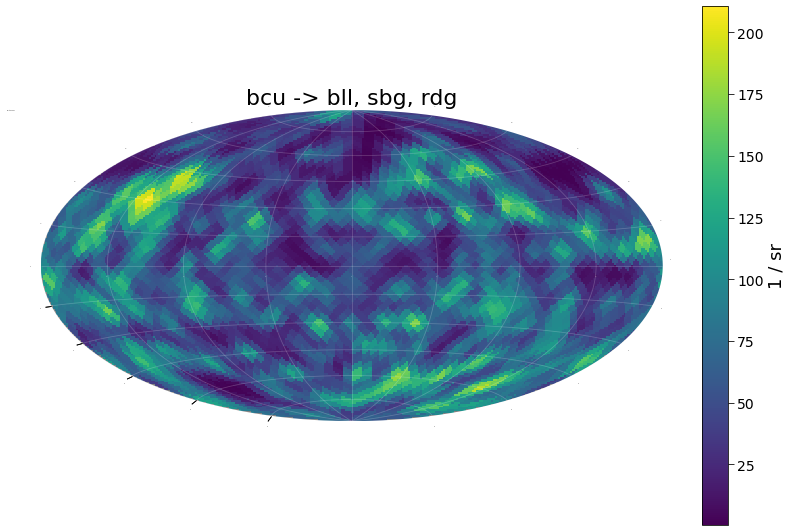

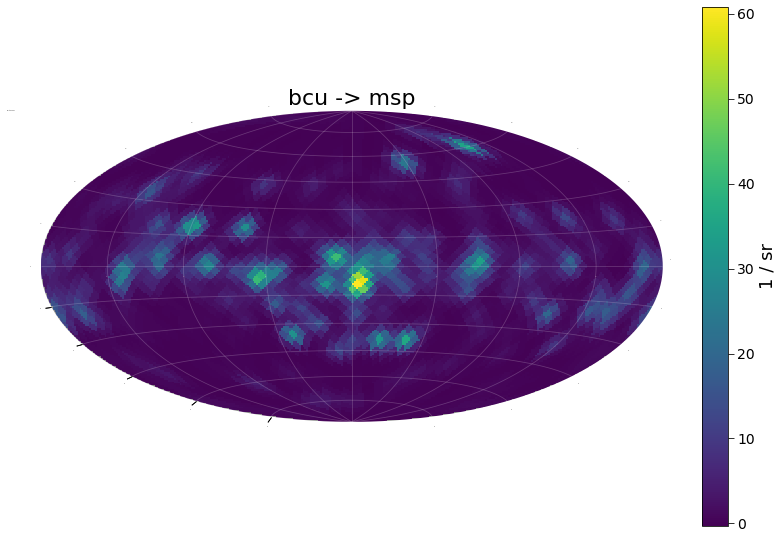

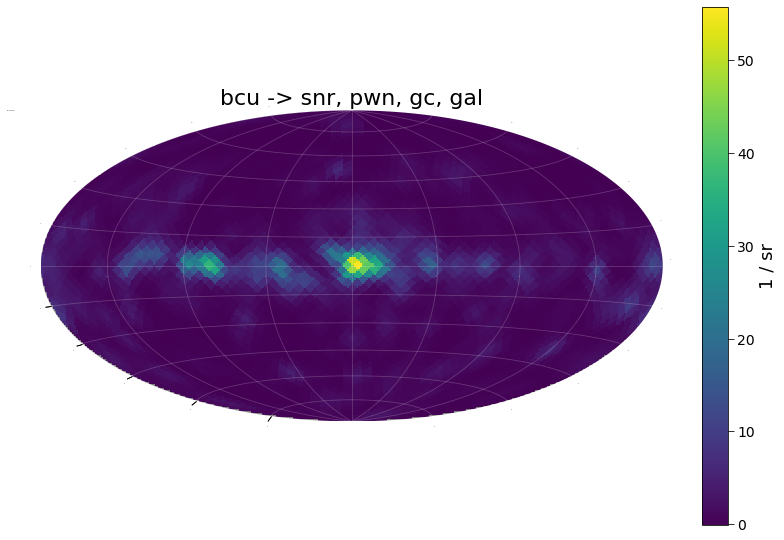

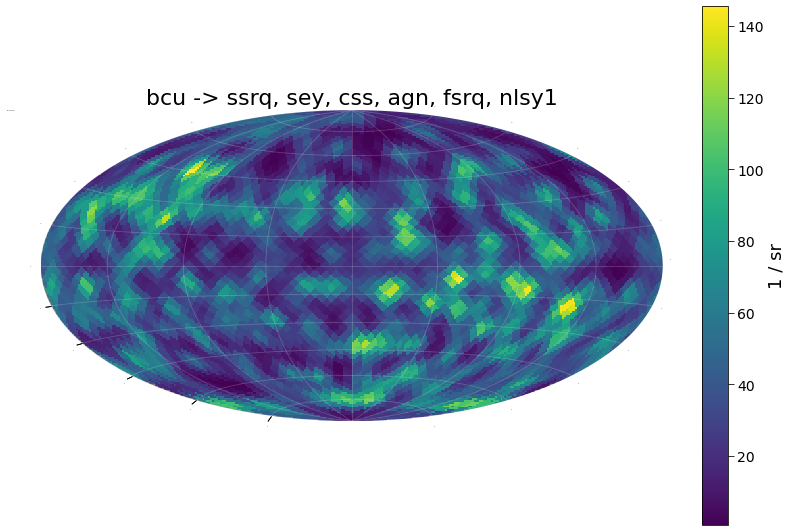

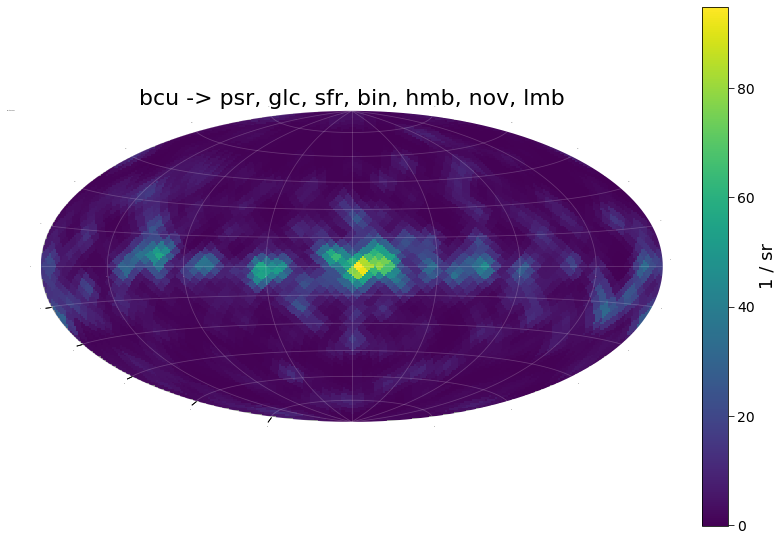

In [211]:
# determine values
save_plots = 1
save_png = 0
for gind in dec_tree_cat_dict.keys():
    weights = cat_df['%i_RF' % gind][mask]
    if plot_var == 'density':
        values = weights
    else:
        values = weights * cat_df[plot_var][mask]
    hmap = np.zeros(npix)
    
    
    for i in hind_uniq:
        if plot_var == 'density':
            hmap[i] = np.sum(weights[i == hind]) / pix_area_sr
        else:
            hmap[i] = np.sum(values[i == hind]) / np.sum(weights[i == hind])
    if smooth:
        hmap = healpy.smoothing(hmap, sigma=sigma_sm)
    geom = HpxGeom(nside, frame='galactic', nest=False)
    hpmap = HpxNDMap(geom, hmap, unit='sr-1')
    
    pyplot.figure()
    hpmap.plot(cmap=cmap, add_cbar=1);
    #fig[0].axes[0].set_xticklabels().set_visible(False)
    title = label + cls2label(dec_tree_cat_dict[gind])
    pyplot.title(title)
    #fig.colorbar()
    if save_plots:
        fn = plots_folder + 'sky_map_%s_%s_node%s.pdf' % (descr_str, plot_var, gind)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn)
        if save_png:
            fn_png = fn.replace('.pdf', '.png')
            pyplot.savefig(fn_png)
